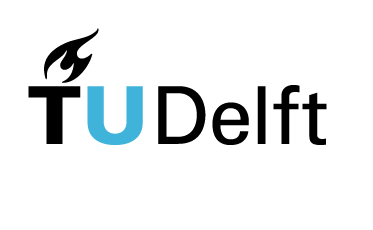
<h1>Triaxial data processing</h1>

This notebook is prepared as an exercise on the unit **Testing and Modelling of Soil Behaviour** from the Master track on Geotechnical engineering at TU Delft\
Elaborated by: Laura Cote & Miguel Cabrera\
Updated: Nov 2026

This notebook consists of the following parts:
1. Triaxial test data structure
2. Processing TX saturation stage
3. Processing TX consolidation stage
4. Processing TX shear stage



**NOTE:**
Today's session will focus on processing only **one** triaxial test (*M02_ISO150kPa_CD_output*). After this session you should process all **7 triaxial tests** provided by the teaching team.

Remember to find all test data in: [SurfDrive](https://surfdrive.surf.nl/files/index.php/s/rTtCgUbAY7kOYFV)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

inputdir='M02_ISO150kPa_CD_output'

## 1. Triaxial test data structure 

The first step is to recognize the data structure. Each file provides information on the triaxial test stage under course, the total elapsed time and stage time, as well as the measured quantities during test. The following lines of code provide a look into this dataset.

In [4]:
#import data

data = pd.read_csv('Data/'+inputdir+'_sat.txt',sep='\s+')
data = pd.DataFrame(data)

print(data)


     Stage totalTime StageTime   Cp   BP      PP
0        #         s         s  kPa  kPa     kPa
1        1         0         0    3    3   -0.83
2        1        60        60    5    6    0.34
3        1       120       120    9    9    3.07
4        1       180       180   12   12    6.16
...    ...       ...       ...  ...  ...     ...
1301     2     77880       420  449  443  442.72
1302     2     77940       480  449  443  442.82
1303     2     78000       540  449  443  442.97
1304     2     78060       600  449  443  442.93
1305     2     78128       624  449  443  443.04

[1306 rows x 6 columns]


<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
C:\Users\farin\AppData\Local\Temp\ipykernel_3688\3977593270.py:3: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv('Data/'+inputdir+'_sat.txt',sep='\s+')


## 2. Processing TX saturation stage 

The second step is to assess the saturation stage of the triaxial test. For this, we will look only at the saturation file, which happens to be the same as the one openned in the previous step. 

      Stage  TotalTime  StageTime   CP   BP      PP
0         1          0          0    3    3   -0.83
1         1         60         60    5    6    0.34
2         1        120        120    9    9    3.07
3         1        180        180   12   12    6.16
4         1        240        240   15   16    8.24
...     ...        ...        ...  ...  ...     ...
1300      2      77880        420  449  443  442.72
1301      2      77940        480  449  443  442.82
1302      2      78000        540  449  443  442.97
1303      2      78060        600  449  443  442.93
1304      2      78128        624  449  443  443.04

[1305 rows x 6 columns]


<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
C:\Users\farin\AppData\Local\Temp\ipykernel_3688\1485882748.py:2: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv('Data/'+inputdir+'_sat.txt',sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP'])


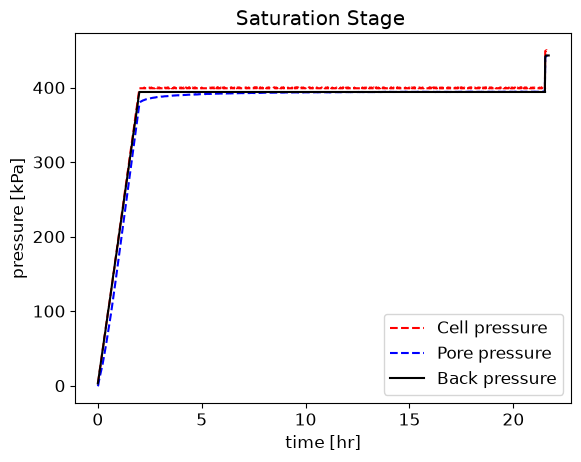

In [5]:
#import data and filter the measurements of interest
data = pd.read_csv('Data/'+inputdir+'_sat.txt',sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP'])
data = pd.DataFrame(data)

print(data)

# convert time structure to hours
t = data.TotalTime/(60*60) #hr
Cell_pre = data.CP
Pore_pre = data.PP
Back_pre = data.BP

#plot data
plt.rcParams.update({'font.size': 12})
fig, ax = plt.subplots(1,1)
ax1=ax

ax1.plot(t, Cell_pre,'r--', label='Cell pressure')
ax1.plot(t, Pore_pre,'b--', label='Pore pressure')
ax1.plot(t, Back_pre,'k-', label='Back pressure')
ax1.legend()
ax1.set_title('Saturation Stage ') 
ax1.set_xlabel(r'time [hr]')
ax1.set_ylabel(r'pressure [kPa]')

# plt.savefig('Plot/Saturation_plot_'+ inputdir +'.pdf')
plt.show()

<div class="alert alert-block alert-warning"> <b>ACTIVITY</b>
    
Evaluate the B-check performed in this test. You can do this by zooming in around the time window where this analysis is performed. Remember that:
$$ B = \frac{\Delta u}{\Delta \sigma_3}$$
where $\Delta u$ is the pore pressure difference and $\Delta \sigma_3$ is the cell pressure.
    
</div>

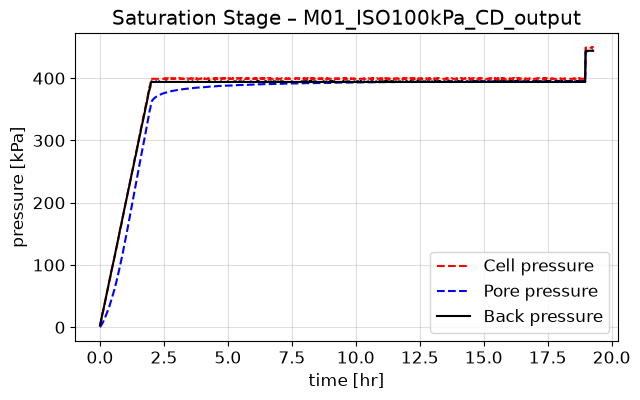

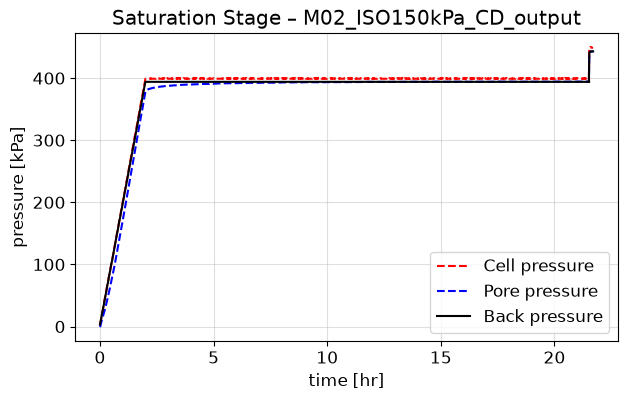

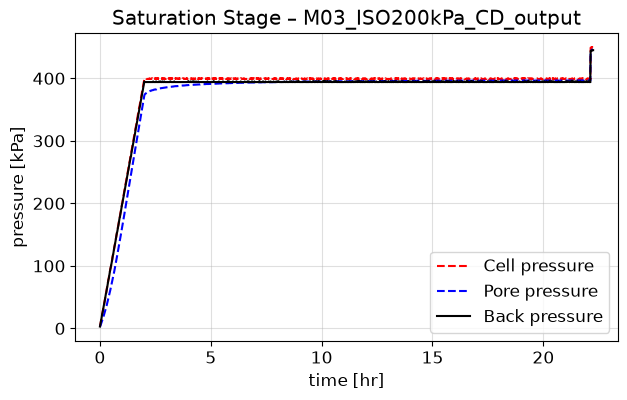

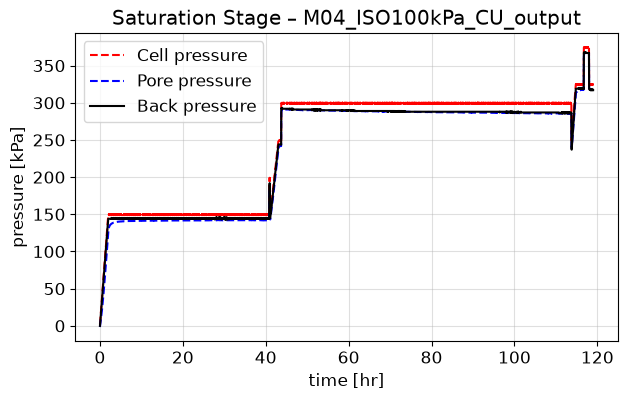

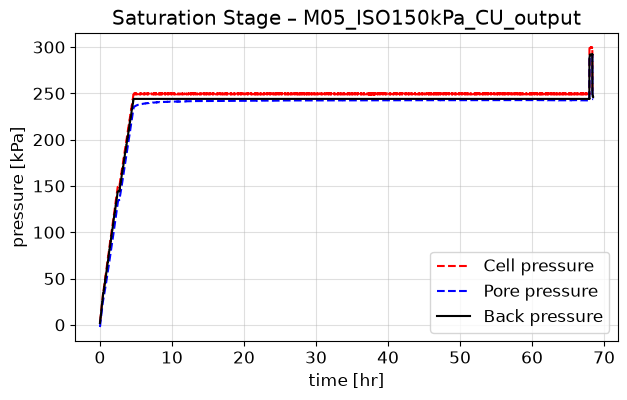

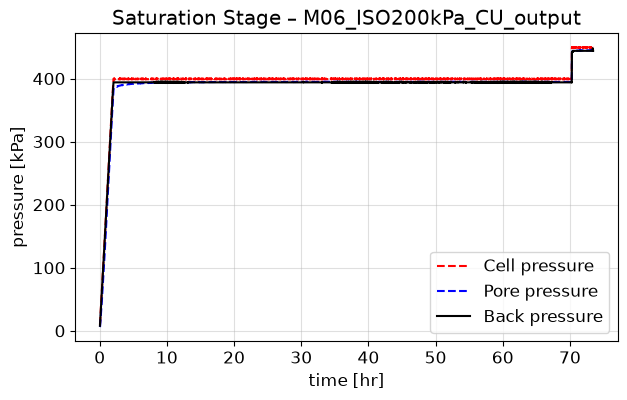

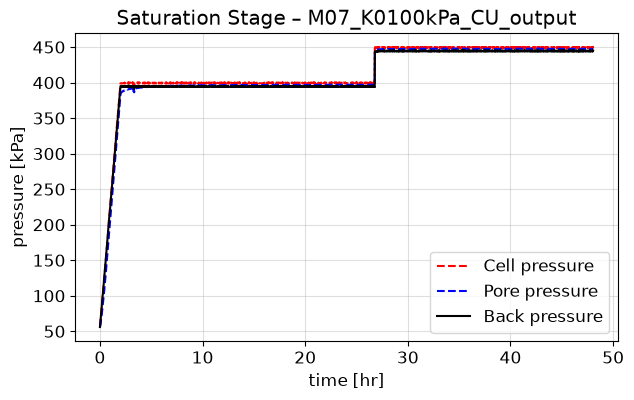


========== M01_ISO100kPa_CD_output ==========
t1 = 17.500 h; nearest reading = 17.500 h
t2 = 19.000 h; nearest reading = 19.000 h
Delta CP = 50.00 kPa
Delta PP = 46.50 kPa
Delta BP = 49.00 kPa
B = Delta PP / Delta CP = 0.930

========== M02_ISO150kPa_CD_output ==========
Hinweis: t2 (25.000 h) lag hinter dem Messende – nutze letzten Wert (21.702 h).
t1 = 20.000 h; nearest reading = 20.000 h
t2 = 21.702 h; nearest reading = 21.702 h
Delta CP = 50.00 kPa
Delta PP = 48.84 kPa
Delta BP = 49.00 kPa
B = Delta PP / Delta CP = 0.977

========== M03_ISO200kPa_CD_output ==========
Hinweis: t2 (25.000 h) lag hinter dem Messende – nutze letzten Wert (22.245 h).
t1 = 20.000 h; nearest reading = 20.000 h
t2 = 22.245 h; nearest reading = 22.245 h
Delta CP = 49.00 kPa
Delta PP = 49.46 kPa
Delta BP = 50.00 kPa
B = Delta PP / Delta CP = 1.009

========== M04_ISO100kPa_CU_output ==========
t1 = 40.000 h; nearest reading = 40.000 h
t2 = 45.000 h; nearest reading = 45.000 h
Delta CP = 151.00 kPa
Delta PP 

,Test,t1 [h],t2 [h],B-Wert
0,M01_ISO100kPa_CD_output,17.5,19.0,0.930
1,M02_ISO150kPa_CD_output,20.0,25.0,0.977
2,M03_ISO200kPa_CD_output,20.0,25.0,1.009
3,M04_ISO100kPa_CU_output,40.0,45.0,0.986
4,M06_ISO200kPa_CU_output,65.0,75.0,1.019
5,M07_K0100kPa_CU_output,25.0,30.0,1.029


In [15]:
tests = [
    'M01_ISO100kPa_CD_output',
    'M02_ISO150kPa_CD_output',
    'M03_ISO200kPa_CD_output',
    'M04_ISO100kPa_CU_output',
    'M05_ISO150kPa_CU_output',
    'M06_ISO200kPa_CU_output',
    'M07_K0100kPa_CU_output',  
]

sat_cols = ['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP']
sat_datasets = {}

plt.rcParams.update({'font.size': 12})

for inputdir in tests:
    # Daten einlesen und im Dictionary für den B-Check merken
    data = pd.read_csv(f'Data/{inputdir}_sat.txt', sep=r'\s+', skiprows=2, names=sat_cols)
    sat_datasets[inputdir] = data

    # Zeit in Stunden umrechnen
    t = data.TotalTime / (60 * 60)  # hr
    Cell_pre = data.CP
    Pore_pre = data.PP
    Back_pre = data.BP

    # Plot erstellen
    fig, ax = plt.subplots(1, 1, figsize=(7, 4))
    ax.plot(t, Cell_pre, 'r--', label='Cell pressure')
    ax.plot(t, Pore_pre, 'b--', label='Pore pressure')
    ax.plot(t, Back_pre, 'k-', label='Back pressure')
    ax.legend()
    ax.set_title(f'Saturation Stage – {inputdir}')
    ax.set_xlabel('time [hr]')
    ax.set_ylabel('pressure [kPa]')
    ax.grid(True, alpha=0.4)

    plt.show()





def calculate_B(data, t1, t2):
    time_hours = pd.to_numeric(data['TotalTime'], errors='raise').to_numpy() / 3600

    if not np.isfinite(t1) or not np.isfinite(t2):
        raise ValueError('t1 and t2 must be finite times in hours.')
    if t2 is None:
        t2 = time_hours.max()
    else:
        if not np.isfinite(t2):
            raise ValueError('t2 must be a finite time in hours or None.')
        if t2 > time_hours.max():
            print(f"Hinweis: t2 ({t2:.3f} h) lag hinter dem Messende – nutze letzten Wert ({time_hours.max():.3f} h).")
            t2 = time_hours.max()
    if t2 <= t1:
        raise ValueError('t2 must be later than t1.')

    time_hours = pd.to_numeric(data['TotalTime'], errors='raise').to_numpy() / 3600
    if t1 < time_hours.min() or t2 > time_hours.max():
        raise ValueError('t1 and t2 must fall within the recorded time range.')

    pos1 = int(np.abs(time_hours - t1).argmin())
    pos2 = int(np.abs(time_hours - t2).argmin())
    if pos1 == pos2:
        raise ValueError('t1 and t2 select the same recorded measurement.')

    before = data.iloc[pos1]
    after = data.iloc[pos2]
    delta_CP = after['CP'] - before['CP']
    if np.isclose(delta_CP, 0):
        raise ValueError('Cell pressure did not change between t1 and t2.')

    delta_PP = after['PP'] - before['PP']
    delta_BP = after['BP'] - before['BP']
    B = delta_PP / delta_CP

    print(f"t1 = {t1:.3f} h; nearest reading = {time_hours[pos1]:.3f} h")
    print(f"t2 = {t2:.3f} h; nearest reading = {time_hours[pos2]:.3f} h")
    print(f"Delta CP = {delta_CP:.2f} kPa")
    print(f"Delta PP = {delta_PP:.2f} kPa")
    print(f"Delta BP = {delta_BP:.2f} kPa")
    print(f"B = Delta PP / Delta CP = {B:.3f}")
    return B

# 1. Für jeden Test das jeweilige Zeitfenster (t1, t2) in Stunden aus den 7 Plots eintragen
b_windows = {
    'M01_ISO100kPa_CD_output': (17.5, 19.0),  # <-- Zeiten jeweils an den Plot anpassen!
    'M02_ISO150kPa_CD_output': (20.0, 25.0),
    'M03_ISO200kPa_CD_output': (20.0, 25.0),
    'M04_ISO100kPa_CU_output': (40.0, 45.0),
    #'M05_ISO150kPa_CU_output': (65.0, 70.0),
    'M06_ISO200kPa_CU_output': (65.0, 75.0),
    'M07_K0100kPa_CU_output': (25.0, 30.0),
}

# 2. Schleife über alle 7 Tests + Sammeln für eine Übersichtstabelle
results = []

for name, (t1, t2) in b_windows.items():
    print(f"\n========== {name} ==========")
    B = calculate_B(sat_datasets[name], t1=t1, t2=t2)
    results.append({
        'Test': name,
        't1 [h]': t1,
        't2 [h]': t2,
        'B-Wert': round(B, 3)
    })

# 3. Kompakte Übersichtstabelle aller 7 Ergebnisse ausgeben
b_summary = pd.DataFrame(results)
display(b_summary)


<div class="alert alert-block alert-info"> In case you are done with this stage, you can have a break and then continue with the next step. </div>

## 3. Processing TX consolidation stage

The third step is to assess the consolidation stage of the triaxial test. For this, we will look only at the <ins>consolidation file</ins>. 

In [5]:
#import data and filter the measurements of interest
data = pd.read_csv('Data/'+inputdir+'_con.txt',sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP', 'ep','ea', 'er','sa_effective','sr_effective','e'])
data = pd.DataFrame(data)

# convert time structure to hours
print(data)
t = data.TotalTime/(60*60) #hr
Cell_pre = data.CP
Pore_pre = data.PP
Back_pre = data.BP
void=data.e
sigma1=data.sa_effective
sigma3=data.sr_effective

      Stage  TotalTime  StageTime   CP   BP      PP        ep        ea  \
0         4          0          0  450  450  447.18  0.000000  0.000000   
1         4        120        120  450  448  447.77 -0.000628  0.000007   
2         4        240        240  449  448  447.14 -0.000741  0.000007   
3         4        360        360  449  448  447.03 -0.000772  0.000007   
4         4        480        480  449  447  447.05 -0.000792  0.000007   
...     ...        ...        ...  ...  ...     ...       ...       ...   
7316      5     877680     869640  522  443  447.39  0.098927  0.101197   
7317      5     877800     869760  522  443  447.34  0.098927  0.101197   
7318      5     877920     869880  522  443  447.07  0.098938  0.101197   
7319      5     878040     870000  522  443  447.12  0.098938  0.101197   
7320      5     878208     870078  522  443  447.08  0.098938  0.101197   

            er  sa_effective  sr_effective         e  
0     0.000000      1.880000      1.880000  

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
C:\Users\farin\AppData\Local\Temp\ipykernel_3764\1812340002.py:2: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv('Data/'+inputdir+'_con.txt',sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP', 'ep','ea', 'er','sa_effective','sr_effective','e'])


<div class="alert alert-block alert-warning"> <b>ACTIVITY</b>
    
Find effective pre-consolidation pressure $\sigma'_p$ reached at this stage. Present your value in kPa.
</div>

Maximum: 137.78 kPa


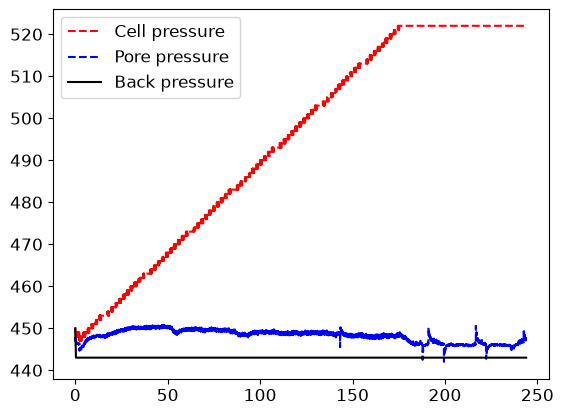

In [6]:
plt.plot(t, Cell_pre,'r--', label='Cell pressure')
plt.plot(t, Pore_pre,'b--', label='Pore pressure')
plt.plot(t, Back_pre,'k-', label='Back pressure')
plt.legend()

def calculate_sigma_p_accent(data):
    max_PP_idx = data["PP"].idxmax()
    max_PP = data.loc[max_PP_idx, "PP"]
    max_CP_at_max_PP = data.loc[max_PP_idx, "CP"]
    sigma_p_accent = max_CP_at_max_PP - max_PP
    print(f"max_CP at max PP = {max_CP_at_max_PP:.2f} kPa")
    print(f"max_PP = {max_PP:.2f} kPa")
    print(f"sigma_p_accent = {sigma_p_accent:.2f} kPa")
    return sigma_p_accent

# Pass the DataFrame loaded from the _con.txt file, not sat_data
sigma_p_prime = data['sa_effective'].max()

print(f"Maximum: {sigma_p_prime:.2f} kPa")

<div class="alert alert-block alert-warning"> <b>ACTIVITY</b>
    
Make the following plots:
* test pressures cell pressure, back pressure, and pore pressure $u$ over time for this test.
* void ratio $e$ over time for this test
* Plot $\sigma'_1$:$\sigma'_3$.
</div>

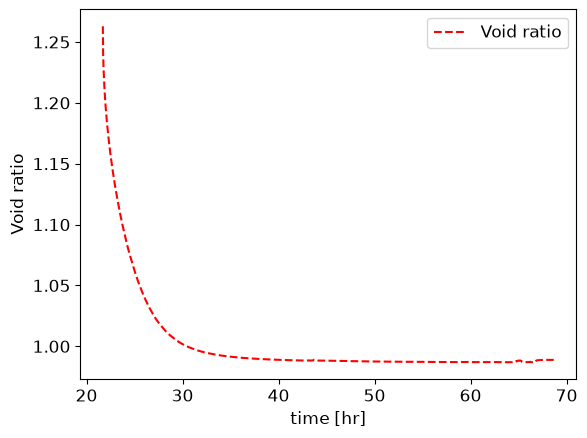

In [ ]:
plt.plot(t, void,'r--', label='Void ratio')
plt.xlabel('time [hr]')
plt.ylabel('Void ratio')
plt.legend()

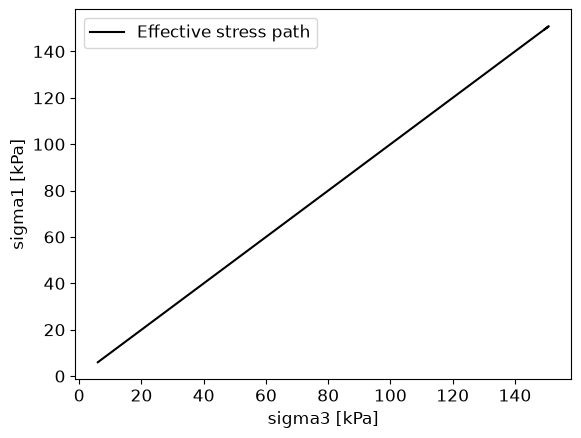

In [ ]:
plt.plot(sigma3, sigma1,'k-', label='Effective stress path')
plt.xlabel('sigma3 [kPa]')
plt.ylabel('sigma1 [kPa]')
plt.legend()

## 4. Processing TX shear stage

The fourth step is to assess the shear stage of the triaxial test. For this, we will look only at the <ins>shear file</ins>. 

In [ ]:
#import data and filter the measurements of interest
data = pd.read_csv('Data/'+inputdir+'_shear.txt',sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'Loadcell','PP', 'ep','ea', 'er', 'deltau','sa_effective','sr_effective','e'])
data = pd.DataFrame(data)

# print(data)
t = data.TotalTime/(60*60) #hr
Cell_pre = data.CP
Pore_pre = data.PP
Back_pre = data.BP
void=data.e
sigma1=data.sa_effective
sigma3=data.sr_effective

axial_strain=data.ea
vol_strain=data.ep

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
C:\Users\koen\AppData\Local\Temp\ipykernel_28964\3696884594.py:2: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv('Data/'+inputdir+'_shear.txt',sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'Loadcell','PP', 'ep','ea', 'er', 'deltau','sa_effective','sr_effective','e'])


<div class="alert alert-block alert-warning"> <b>ACTIVITY</b>
    
Compute the mean stress $p$, mean effective stress $p'$, deviatoric stress $q$, axial strains $\varepsilon_a$ and volumetric strains $\varepsilon_p$ for this test. With this information plot the following:
* stress paths in the $q$ : $p$ plane.
* stress : strain diagram $q$ : $\varepsilon_a$
* volumetric strains : axial strain $\varepsilon_p$ : $\varepsilon_a$
</div>

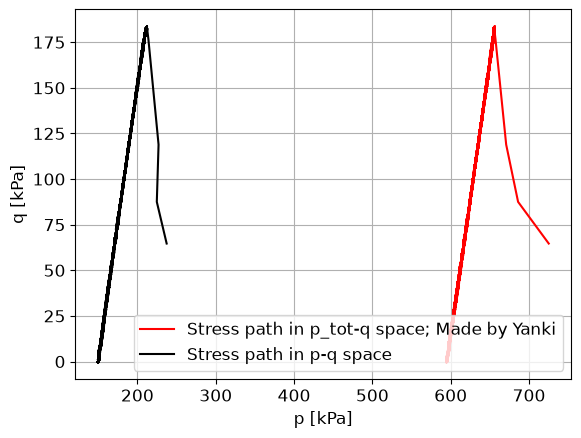

In [ ]:
p = (sigma1 + 2*sigma3)/3
p_tot = p + Pore_pre
q = sigma1 - sigma3
e_a = axial_strain
e_p = vol_strain

plt.plot(p_tot, q,'r-', label='Stress path in p_tot-q space; Made by Yanki')
plt.plot(p, q,'k-', label='Stress path in p-q space')
plt.legend()
plt.xlabel('p [kPa]')
plt.ylabel('q [kPa]')
plt.grid()

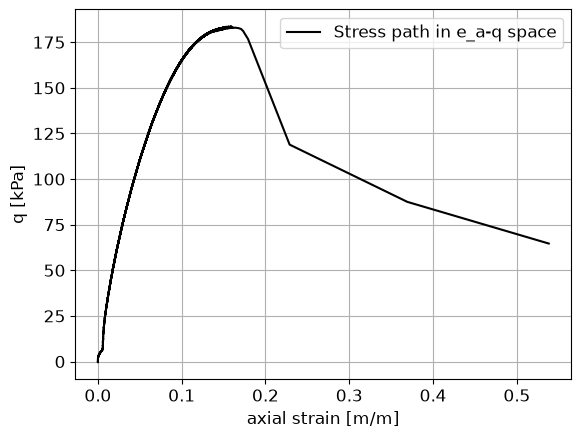

In [ ]:
plt.plot(e_a, q,'k-', label='Stress path in e_a-q space')
plt.xlabel('axial strain [m/m]')
plt.ylabel('q [kPa]')
plt.legend()
plt.grid()

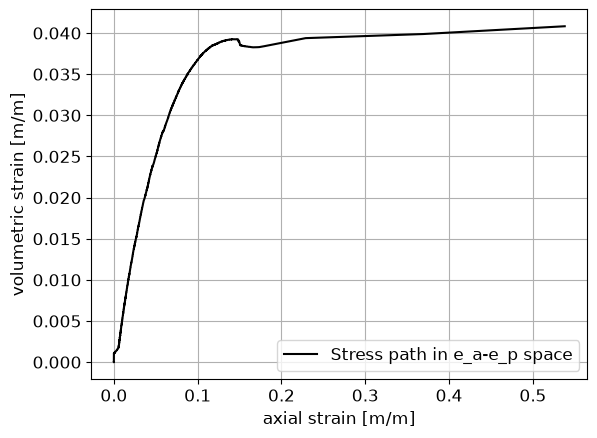

In [ ]:
plt.plot(e_a, e_p,'k-', label='Stress path in e_a-e_p space')
plt.xlabel('axial strain [m/m]')
plt.ylabel('volumetric strain [m/m]')
plt.legend()
plt.grid()

<div class="alert alert-block alert-warning"> <b>ACTIVITY</b>

Find the initial mean effective stress $p'_0$ and initial void ratio $e_0$ for this test
</div>

In [ ]:
po = p[0]
void_initial = void[0]
print(f"Initial mean effective stress po = {po:.2f} kPa")
print(f"Initial void ratio = {void_initial:.3f}")

Initial mean effective stress po = 149.72 kPa
Initial void ratio = 0.989


<div class="alert alert-block alert-success"> <b>HOMEWORK</b> 
    
Repeat the aforementioned analysis for all tests found in [SurfDrive](https://surfdrive.surf.nl/files/index.php/s/rTtCgUbAY7kOYFV) and plot all tests together for each triaxial stage. These will be used in next week session for estimating $c_v$, $E_{50}$, $c$, $\varphi$, $M$, and $\psi$.
</div>

In [ ]:
def process_test(test_name, t1, t2):
    # Load saturation data
    sat_data = pd.read_csv(f'Data/{test_name}_sat.txt', sep=r'\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP'])
    
    # Calculate B for the saturation stage
    B = calculate_B(sat_data, t1, t2)
    
    # Load consolidation data
    con_data = pd.read_csv(f'Data/{test_name}_con.txt', sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP', 'ep','ea', 'er','sa_effective','sr_effective','e'])
    
    # Calculate sigma_p_accent for the consolidation stage
    sigma_p_accent = calculate_sigma_p_accent(con_data)
    
    # Load shear data
    shear_data = pd.read_csv(f'Data/{test_name}_shear.txt', sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'Loadcell','PP', 'ep','ea', 'er', 'deltau','sa_effective','sr_effective','e'])
    
    # Additional processing can be added here as needed
    return {
    "sat": sat_data,
    "con": con_data,
    "shear": shear_data,
}

b_times = {
    "M01_ISO100kPa_CD_output": (18, 19.1),
    "M02_ISO150kPa_CD_output": (15, 21.6),
    "M03_ISO200kPa_CD_output": (22, 22.2),
    "M04_ISO100kPa_CU_output": (115.5, 117.5),
    "M05_ISO150kPa_CU_output": (67, 68.1),
    "M06_ISO200kPa_CU_output": (70, 72),
    "M07_K0100kPa_CU_output": (25, 27.5),
}
all_data = {}

for test_name, (t1, t2) in b_times.items():
    if t1 is None or t2 is None:
        raise ValueError(f"Vul t1 en t2 in uren in voor {test_name}")

    print(f"\nProcessing {test_name}")
    all_data[test_name] = process_test(test_name, t1, t2)
    



<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\s'
C:\Users\koen\AppData\Local\Temp\ipykernel_28964\3983471848.py:9: SyntaxWarning: invalid escape sequence '\s'
  con_data = pd.read_csv(f'Data/{test_name}_con.txt', sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'PP', 'ep','ea', 'er','sa_effective','sr_effective','e'])
C:\Users\koen\AppData\Local\Temp\ipykernel_28964\3983471848.py:15: SyntaxWarning: invalid escape sequence '\s'
  shear_data = pd.read_csv(f'Data/{test_name}_shear.txt', sep='\s+', skiprows=2, names=['Stage', 'TotalTime', 'StageTime', 'CP', 'BP', 'Loadcell','PP', 'ep','ea', 'er', 'deltau','sa_effective','sr_effective','e'])



Processing M01_ISO100kPa_CD_output
t1 = 18.000 h; nearest reading = 18.000 h
t2 = 19.100 h; nearest reading = 19.100 h
Delta CP = 49.00 kPa
Delta PP = 48.95 kPa
Delta BP = 50.00 kPa
B = Delta PP / Delta CP = 0.999
max_CP at max PP = 549.00 kPa
max_PP = 542.98 kPa
sigma_p_accent = 6.02 kPa

Processing M02_ISO150kPa_CD_output
t1 = 15.000 h; nearest reading = 15.000 h
t2 = 21.600 h; nearest reading = 21.600 h
Delta CP = 51.00 kPa
Delta PP = 48.39 kPa
Delta BP = 49.00 kPa
B = Delta PP / Delta CP = 0.949
max_CP at max PP = 594.00 kPa
max_PP = 587.19 kPa
sigma_p_accent = 6.81 kPa

Processing M03_ISO200kPa_CD_output
t1 = 22.000 h; nearest reading = 22.000 h
t2 = 22.200 h; nearest reading = 22.200 h
Delta CP = 49.00 kPa
Delta PP = 48.98 kPa
Delta BP = 51.00 kPa
B = Delta PP / Delta CP = 1.000
max_CP at max PP = 643.00 kPa
max_PP = 638.97 kPa
sigma_p_accent = 4.03 kPa

Processing M04_ISO100kPa_CU_output
t1 = 115.500 h; nearest reading = 115.500 h
t2 = 117.500 h; nearest reading = 117.500 h
Del

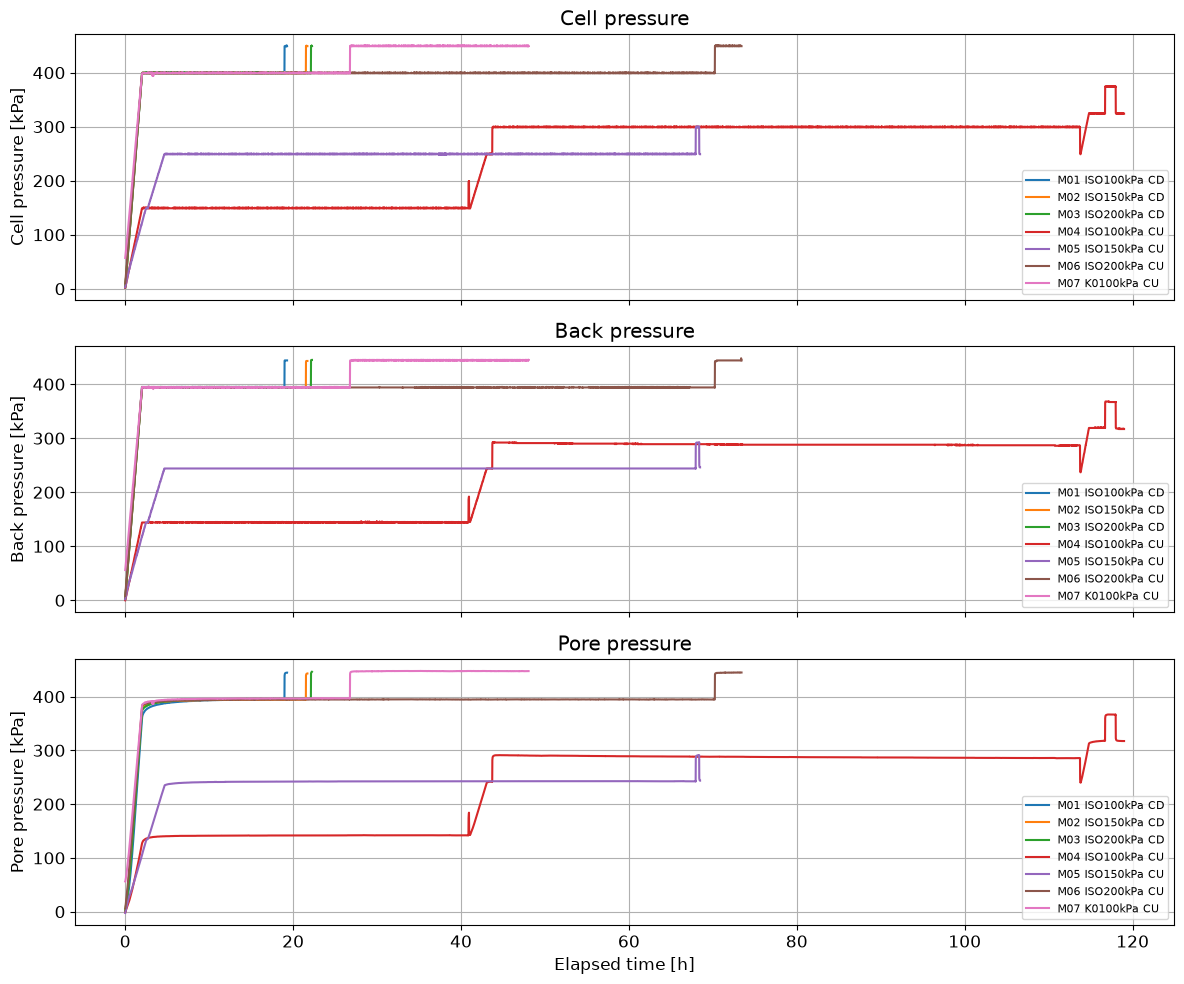

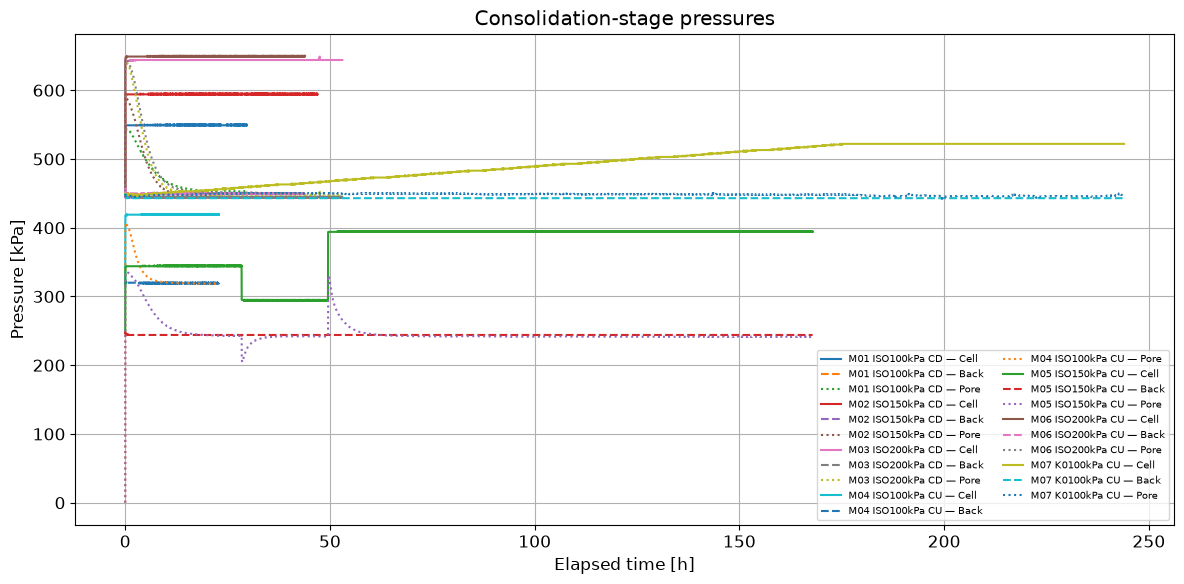

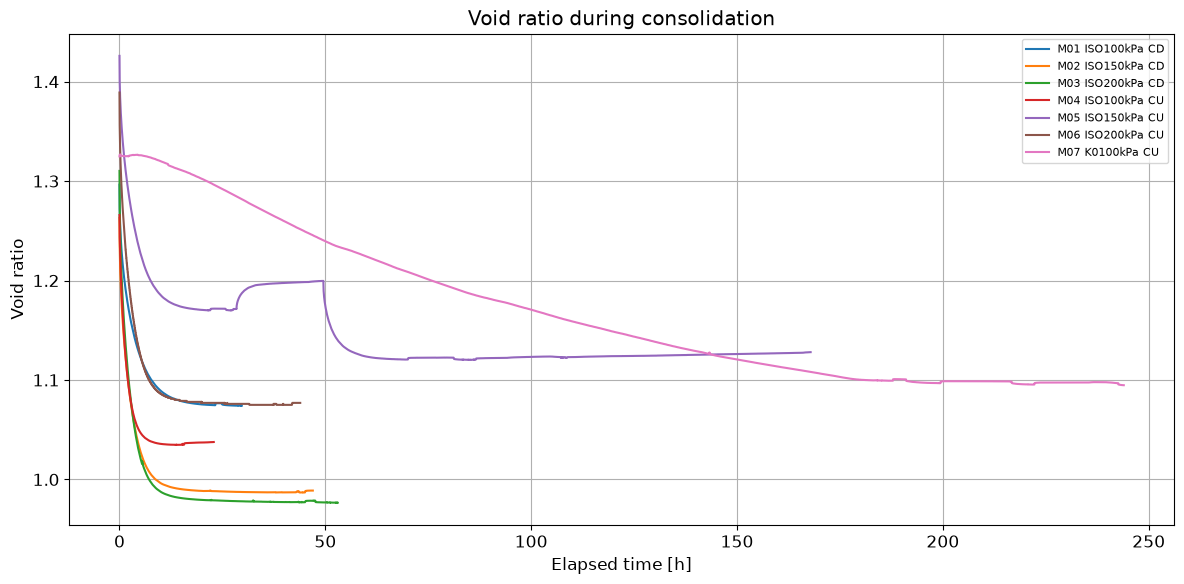

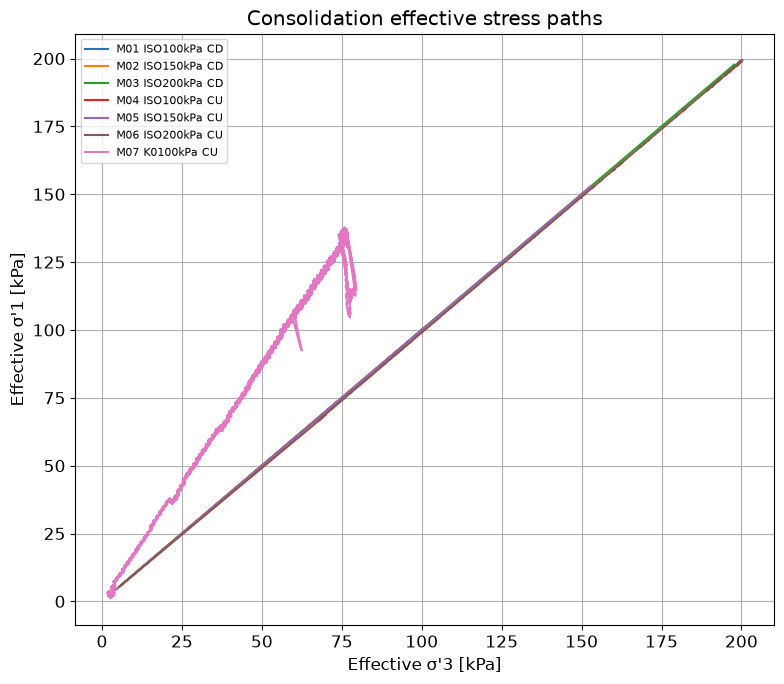

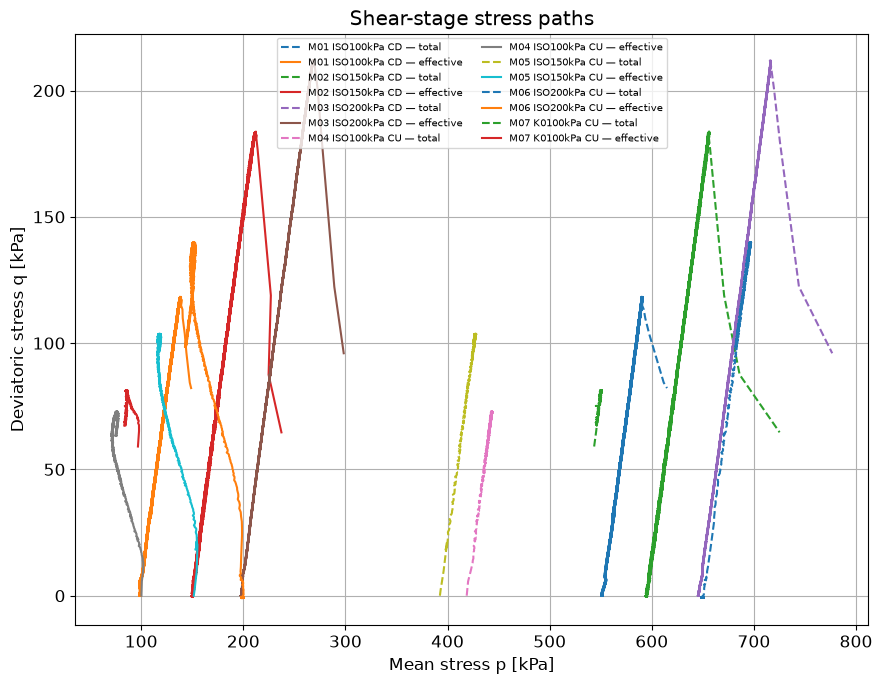

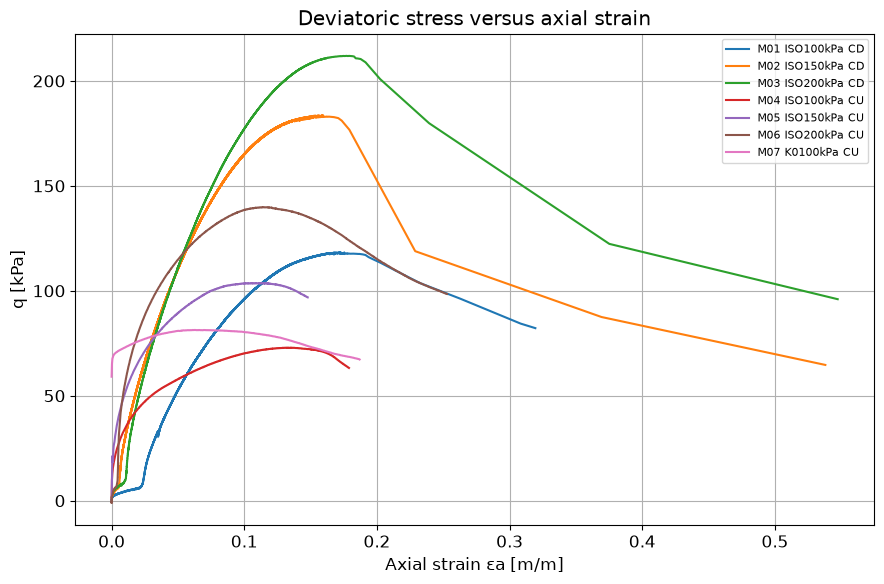

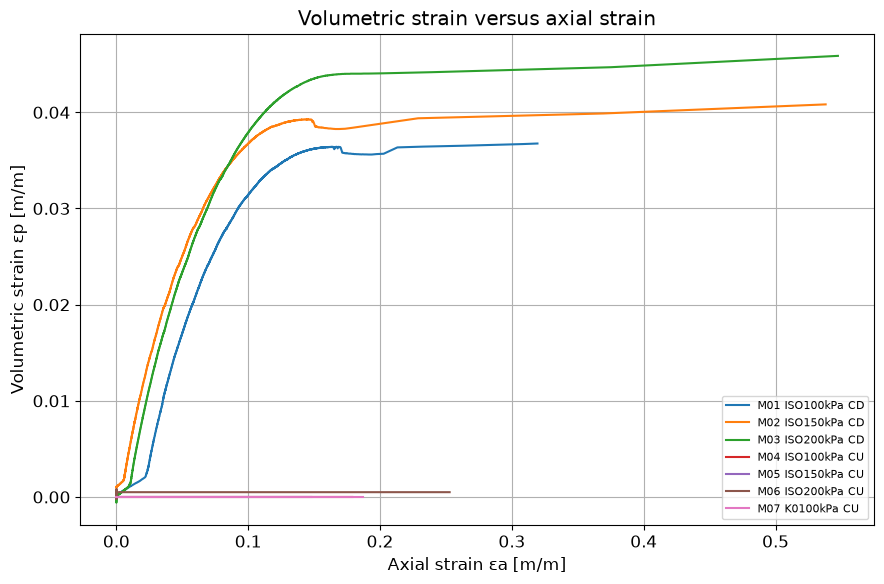

In [ ]:
# Use consistent labels and elapsed time for comparing tests
test_labels = {
    name: name.replace('_output', '').replace('_', ' ')
    for name in all_data
}

def elapsed_hours(df):
    return (df['TotalTime'] - df['TotalTime'].iloc[0]) / 3600


# Saturation-stage pressures
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for test_name, stages in all_data.items():
    df = stages['sat']
    time_hr = elapsed_hours(df)
    for ax, column, label in zip(
        axes, ['CP', 'BP', 'PP'],
        ['Cell pressure', 'Back pressure', 'Pore pressure']
    ):
        ax.plot(time_hr, df[column], label=test_labels[test_name])
        ax.set_ylabel(f'{label} [kPa]')
        ax.set_title(label)
        ax.grid(True)
        ax.legend(fontsize=8)

axes[-1].set_xlabel('Elapsed time [h]')
fig.tight_layout()
plt.show()


# Consolidation-stage pressures
fig, ax = plt.subplots(figsize=(12, 6))
for test_name, stages in all_data.items():
    df = stages['con']
    time_hr = elapsed_hours(df)
    ax.plot(time_hr, df['CP'], label=f'{test_labels[test_name]} — Cell')
    ax.plot(time_hr, df['BP'], '--', label=f'{test_labels[test_name]} — Back')
    ax.plot(time_hr, df['PP'], ':', label=f'{test_labels[test_name]} — Pore')
ax.set(title='Consolidation-stage pressures', xlabel='Elapsed time [h]',
       ylabel='Pressure [kPa]')
ax.grid(True)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


# Consolidation-stage void ratio
fig, ax = plt.subplots(figsize=(12, 6))
for test_name, stages in all_data.items():
    df = stages['con']
    ax.plot(elapsed_hours(df), df['e'], label=test_labels[test_name])
ax.set(title='Void ratio during consolidation', xlabel='Elapsed time [h]',
       ylabel='Void ratio')
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# Consolidation-stage effective stress path: sigma'1 versus sigma'3
fig, ax = plt.subplots(figsize=(8, 7))
for test_name, stages in all_data.items():
    df = stages['con']
    ax.plot(df['sr_effective'], df['sa_effective'], label=test_labels[test_name])
ax.set(title='Consolidation effective stress paths',
       xlabel="Effective σ'3 [kPa]", ylabel="Effective σ'1 [kPa]")
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# Shear-stage stress paths and strain plots
fig, ax = plt.subplots(figsize=(9, 7))
for test_name, stages in all_data.items():
    df = stages['shear']
    sigma1 = df['sa_effective']
    sigma3 = df['sr_effective']
    p_eff = (sigma1 + 2 * sigma3) / 3
    q = sigma1 - sigma3
    p_total = p_eff + df['PP']

    ax.plot(p_total, q, '--', label=f'{test_labels[test_name]} — total')
    ax.plot(p_eff, q, label=f'{test_labels[test_name]} — effective')
ax.set(title='Shear-stage stress paths', xlabel='Mean stress p [kPa]',
       ylabel='Deviatoric stress q [kPa]')
ax.grid(True)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(9, 6))
for test_name, stages in all_data.items():
    df = stages['shear']
    q = df['sa_effective'] - df['sr_effective']
    ax.plot(df['ea'], q, label=test_labels[test_name])
ax.set(title='Deviatoric stress versus axial strain',
       xlabel='Axial strain εa [m/m]', ylabel='q [kPa]')
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(9, 6))
for test_name, stages in all_data.items():
    df = stages['shear']
    ax.plot(df['ea'], df['ep'], label=test_labels[test_name])
ax.set(title='Volumetric strain versus axial strain',
       xlabel='Axial strain εa [m/m]', ylabel='Volumetric strain εp [m/m]')
ax.grid(True)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()